<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/Practical_11_by_Tushar_Guleria(GF202459441).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 11

A sunspot is a region on the Sun’s surface (photo-sphere) that is marked by a lower temperature than its environment.
These reduced temperatures are caused by concentrations of magnetic field flux that inhibit convection by an effect similar to eddy current brakes.
Sunspots usually appear in pairs of opposite magnetic polarity.
  Their number varies according to the approximately 11-year solar cycle. The data we will be working on is the “Monthly mean total sunspot number”, for each month from January 1749 to November 2018. This data is collected, curated and made publicly available by the World Data Center for the production, preservation and dissemination of the international sunspot number. What you have to do:

  Step 1. Plot the data over the years to see what the distribution might be like
  
  Step 2. Model the phenomenon with a gamma distribution, with a new cycle resetting every 12 years
  
  Step 3. Histogram of sunspot counts
  
  Step 4. a=4, and b =10 so plot MNMC for groups: First 50 samples, All samples, Last 50 samples
  
  Step 5. Visualise the traces of and b and the histogram of the traces. [Here you are going to drop some values known as burn out]
  
  Step 6. Prediction time of a and b


## Step 1: Loading and Visualizing the Monthly Mean Sunspot Dataset

**Objective:** Load the monthly mean total sunspot number dataset (January 1749 to November 2018) and visualize the variation in sunspot activity over time.

- `pd.read_csv(..., sep=";")` loads the semicolon-separated dataset directly from SILSO.
- `pd.to_datetime()` combines the `year` and `month` columns into a proper datetime format.
- `plt.plot()` creates a time-series line graph to observe repeating solar cycles.

,year,month,decimal_date,sunspot_number,standard_deviation,observations,marker,date
0,1749,1,1749.042,96.7,-1.0,-1,1,1749-01-01
1,1749,2,1749.123,104.3,-1.0,-1,1,1749-02-01
2,1749,3,1749.204,116.7,-1.0,-1,1,1749-03-01
3,1749,4,1749.288,92.8,-1.0,-1,1,1749-04-01
4,1749,5,1749.371,141.7,-1.0,-1,1,1749-05-01


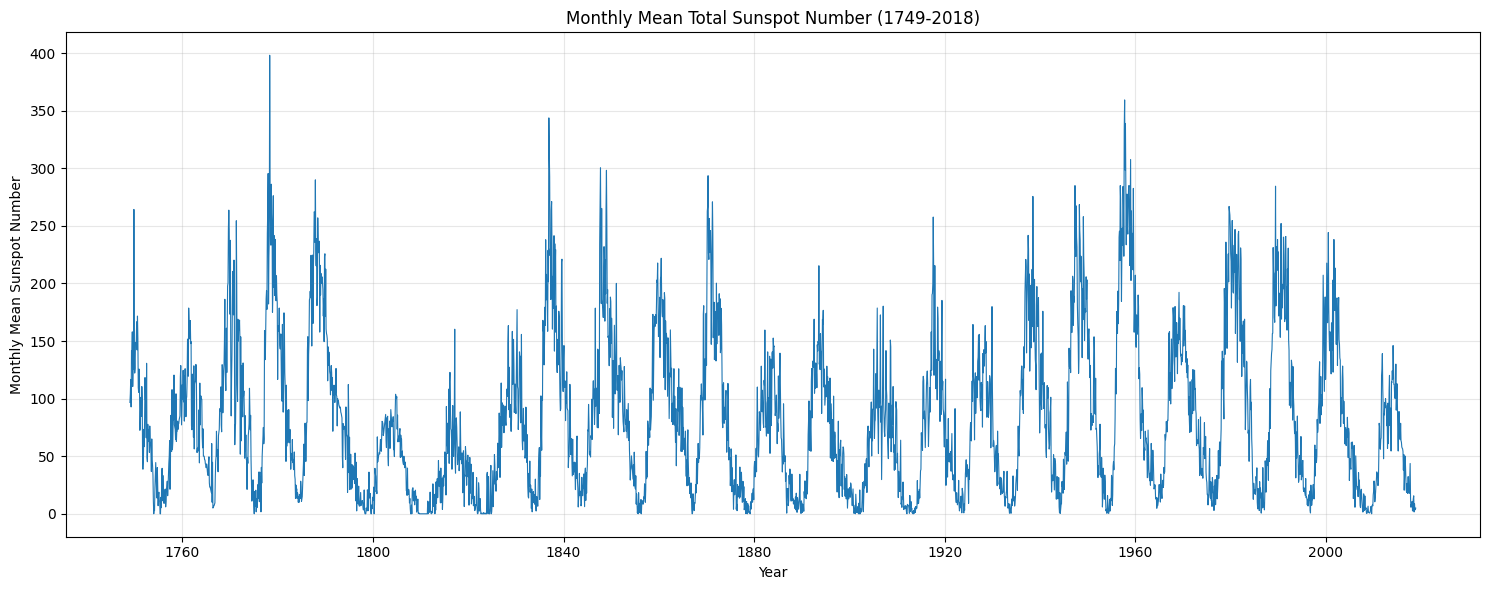

Total observations: 3239
Start date: 1749-01-01 00:00:00
End date: 2018-11-01 00:00:00


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Official SILSO monthly sunspot dataset URL (Colab-ready)
url = "https://www.sidc.be/SILSO/DATA/SN_m_tot_V2.0.csv"

# Load dataset
columns = [
    "year",
    "month",
    "decimal_date",
    "sunspot_number",
    "standard_deviation",
    "observations",
    "marker"
]

df = pd.read_csv(url, sep=";", header=None, names=columns)

# Keep the assignment's date range: January 1749 to November 2018
df = df[
    ((df["year"] > 1749) | ((df["year"] == 1749) & (df["month"] >= 1))) &
    ((df["year"] < 2018) | ((df["year"] == 2018) & (df["month"] <= 11)))
].copy()

# Create a proper date column
df["date"] = pd.to_datetime(
    dict(year=df["year"], month=df["month"], day=1)
)

# Display first five records
display(df.head())

# Plot sunspot activity over time
plt.figure(figsize=(15, 6))
plt.plot(
    df["date"],
    df["sunspot_number"],
    linewidth=0.8
)
plt.title("Monthly Mean Total Sunspot Number (1749-2018)")
plt.xlabel("Year")
plt.ylabel("Monthly Mean Sunspot Number")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display dataset information
print("Total observations:", len(df))
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

## Step 2: Modeling Sunspot Counts Using a Gamma Distribution

**Objective:** Model monthly sunspot observations using a Gamma probability distribution, with a new cycle beginning every 12 years.

The Gamma distribution represents positive, skewed numerical data using two parameters:
- **Shape parameter ($a$ or $\alpha$):** Controls the shape of the distribution.
- **Scale parameter ($b$ or $\theta$):** Controls the spread of the distribution.

We divide the observations into 12-year groups (144 months per cycle):
$$\text{cycle} = \left\lfloor \frac{\text{year} - 1749}{12} \right\rfloor + 1$$

> **Note:** Because the Gamma distribution is defined strictly for positive values, zero sunspot observations are excluded during fitting. The 12-year grouping is a modeling assumption for this assignment rather than the exact physical length of every solar cycle.

,Cycle,Observations,Shape (a),Scale (b)
0,1,144,1.968,37.431
1,2,144,2.279,44.080
2,3,144,1.212,79.531
3,4,144,2.000,57.620
4,5,144,1.534,27.990
5,6,144,1.140,33.191
6,7,144,1.139,55.385
7,8,144,1.126,83.658
8,9,144,1.450,70.540
9,10,144,1.825,50.792


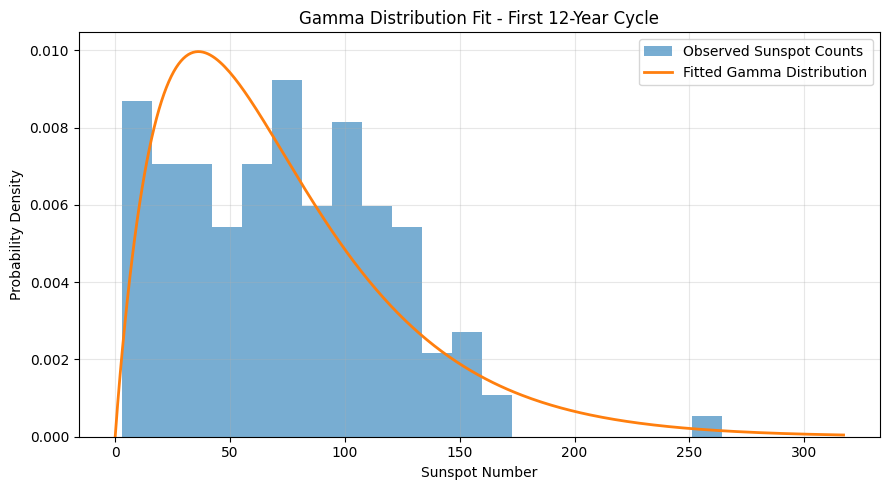

First cycle shape parameter (a): 1.968
First cycle scale parameter (b): 37.431


In [2]:
from scipy.stats import gamma

# Create a copy of the dataset
gamma_df = df.copy()

# Assign a new cycle every 12 years
gamma_df["cycle"] = ((gamma_df["year"] - 1749) // 12) + 1

# Store Gamma distribution parameters
cycle_results = []

# Fit a Gamma distribution separately for each cycle
for cycle_number, group in gamma_df.groupby("cycle"):
    # Remove zero values because Gamma distribution requires positive data
    positive_values = group.loc[
        group["sunspot_number"] > 0,
        "sunspot_number"
    ]

    # Fit Gamma distribution
    shape, loc, scale = gamma.fit(
        positive_values,
        floc=0
    )

    cycle_results.append({
        "Cycle": cycle_number,
        "Observations": len(group),
        "Shape (a)": shape,
        "Scale (b)": scale
    })

# Display fitted parameters
gamma_results = pd.DataFrame(cycle_results)
display(gamma_results.round(3))

# Plot the Gamma distribution for the first cycle
first_cycle = gamma_df[gamma_df["cycle"] == 1]
positive_values = first_cycle.loc[
    first_cycle["sunspot_number"] > 0,
    "sunspot_number"
]
shape, loc, scale = gamma.fit(positive_values, floc=0)

# Generate values for the Gamma probability density curve
x = np.linspace(0, positive_values.max() * 1.2, 300)
pdf = gamma.pdf(x, a=shape, loc=0, scale=scale)

plt.figure(figsize=(9, 5))
plt.hist(
    positive_values,
    bins=20,
    density=True,
    alpha=0.6,
    label="Observed Sunspot Counts"
)
plt.plot(
    x,
    pdf,
    linewidth=2,
    label="Fitted Gamma Distribution"
)
plt.title("Gamma Distribution Fit - First 12-Year Cycle")
plt.xlabel("Sunspot Number")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("First cycle shape parameter (a):", round(shape, 3))
print("First cycle scale parameter (b):", round(scale, 3))

### Conclusion (Step 2)
The monthly sunspot observations were divided into 12-year groups, and a Gamma distribution was fitted separately to the positive observations in each group. The fitted Gamma probability density curve for the first cycle aligns well with the right-skewed observed sunspot counts, establishing the probability model for subsequent MCMC analysis.

## Step 3: Plotting the Histogram of Sunspot Counts

**Objective:** Visualize the frequency distribution of monthly sunspot numbers across the entire dataset using a histogram (`bins=30`) to inspect skewness and spread.

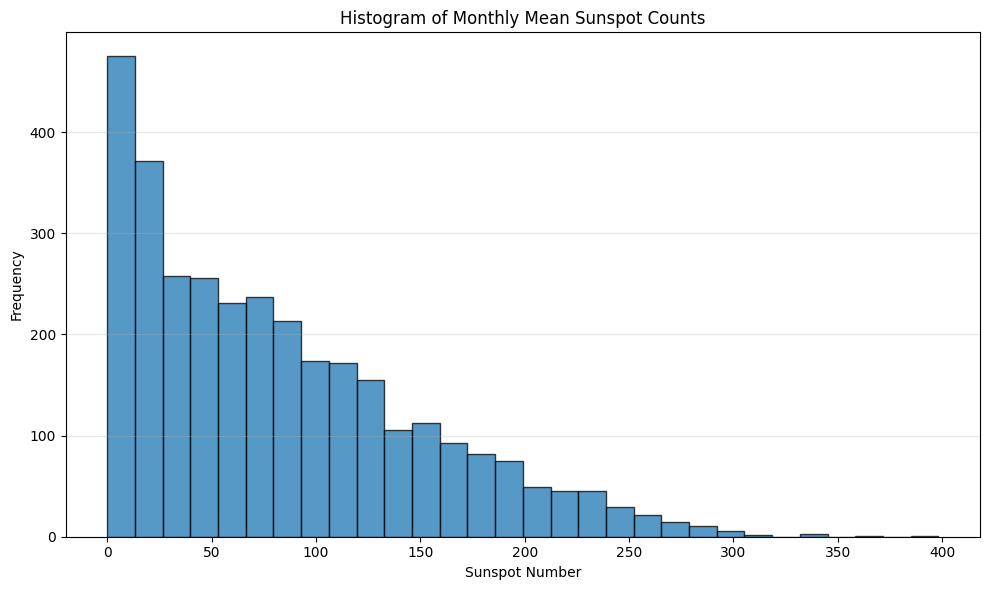

Minimum sunspot count: 0.0
Maximum sunspot count: 398.2
Average sunspot count: 82.39
Median sunspot count: 68.3


In [6]:
# Extract monthly sunspot numbers
sunspot_counts = df["sunspot_number"]

# Plot histogram
plt.figure(figsize=(10, 6))
plt.hist(
    sunspot_counts,
    bins=30,
    edgecolor="black",
    alpha=0.75
)
plt.title("Histogram of Monthly Mean Sunspot Counts")
plt.xlabel("Sunspot Number")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display basic information
print("Minimum sunspot count:", sunspot_counts.min())
print("Maximum sunspot count:", sunspot_counts.max())
print("Average sunspot count:", round(sunspot_counts.mean(), 2))
print("Median sunspot count:", round(sunspot_counts.median(), 2))

### Conclusion (Step 3)
The histogram confirms that the monthly mean sunspot counts follow a strong right-skewed distribution, justifying the use of a Gamma distribution for statistical modeling.

## Step 4: Applying Markov Chain Monte Carlo (MCMC)

**Objective:** Estimate the shape parameter ($a$) and scale parameter ($b$) of the Gamma distribution using the **Metropolis-Hastings** MCMC algorithm.

- **Initial shape parameter:** $a = 4$
- **Initial scale parameter:** $b = 10$
- **Iterations:** $5,000$

We examine three segments of the Markov chain:
1. **First 50 samples:** Shows the initial transient movement of the chain from the starting point.
2. **All samples:** Shows the complete sampling trajectory.
3. **Last 50 samples:** Shows stationary mixing behavior near the end of the chain.

In [7]:
from scipy.special import gammaln

# Use positive sunspot observations
data = df.loc[
    df["sunspot_number"] > 0,
    "sunspot_number"
].to_numpy()

# Initial values
initial_a = 4
initial_b = 10

# Number of MCMC iterations
n_iterations = 5000

# Random number generator
rng = np.random.default_rng(42)

# Log posterior function
def log_posterior(log_params):
    # Convert log parameters into positive values
    a = np.exp(log_params[0])
    b = np.exp(log_params[1])

    # Gamma Log-Likelihood
    n = len(data)
    log_likelihood = (
        (a - 1) * np.sum(np.log(data))
        - np.sum(data) / b
        - n * gammaln(a)
        - n * a * np.log(b)
    )

    # Broad log-normal priors
    log_prior = (
        -0.5 * ((log_params[0] - np.log(4)) / 2) ** 2
        - 0.5 * ((log_params[1] - np.log(10)) / 2) ** 2
    )

    return log_likelihood + log_prior

# Initialize the chain in log space
current = np.log([initial_a, initial_b])
current_posterior = log_posterior(current)

# Store MCMC samples
chain = np.zeros((n_iterations, 2))
accepted = 0

# Metropolis-Hastings sampling
for i in range(n_iterations):
    # Generate proposed values
    proposal = current + rng.normal(
        loc=0,
        scale=[0.08, 0.08],
        size=2
    )
    proposal_posterior = log_posterior(proposal)

    # Calculate acceptance probability
    log_acceptance = proposal_posterior - current_posterior

    # Accept or reject proposal
    if np.log(rng.random()) < min(0, log_acceptance):
        current = proposal
        current_posterior = proposal_posterior
        accepted += 1

    # Store current parameter values
    chain[i] = np.exp(current)

# Convert samples into a DataFrame
mcmc_df = pd.DataFrame(
    chain,
    columns=["a", "b"]
)

print("Total MCMC iterations:", n_iterations)
print("Accepted proposals:", accepted)
print("Acceptance rate:", round(accepted / n_iterations * 100, 2), "%")
display(mcmc_df.head())

Total MCMC iterations: 5000
Accepted proposals: 504
Acceptance rate: 10.08 %


,a,b
0,4.000000,10.000000
1,4.000000,10.000000
2,4.000000,10.000000
3,3.736132,10.728856
4,3.755920,11.741343


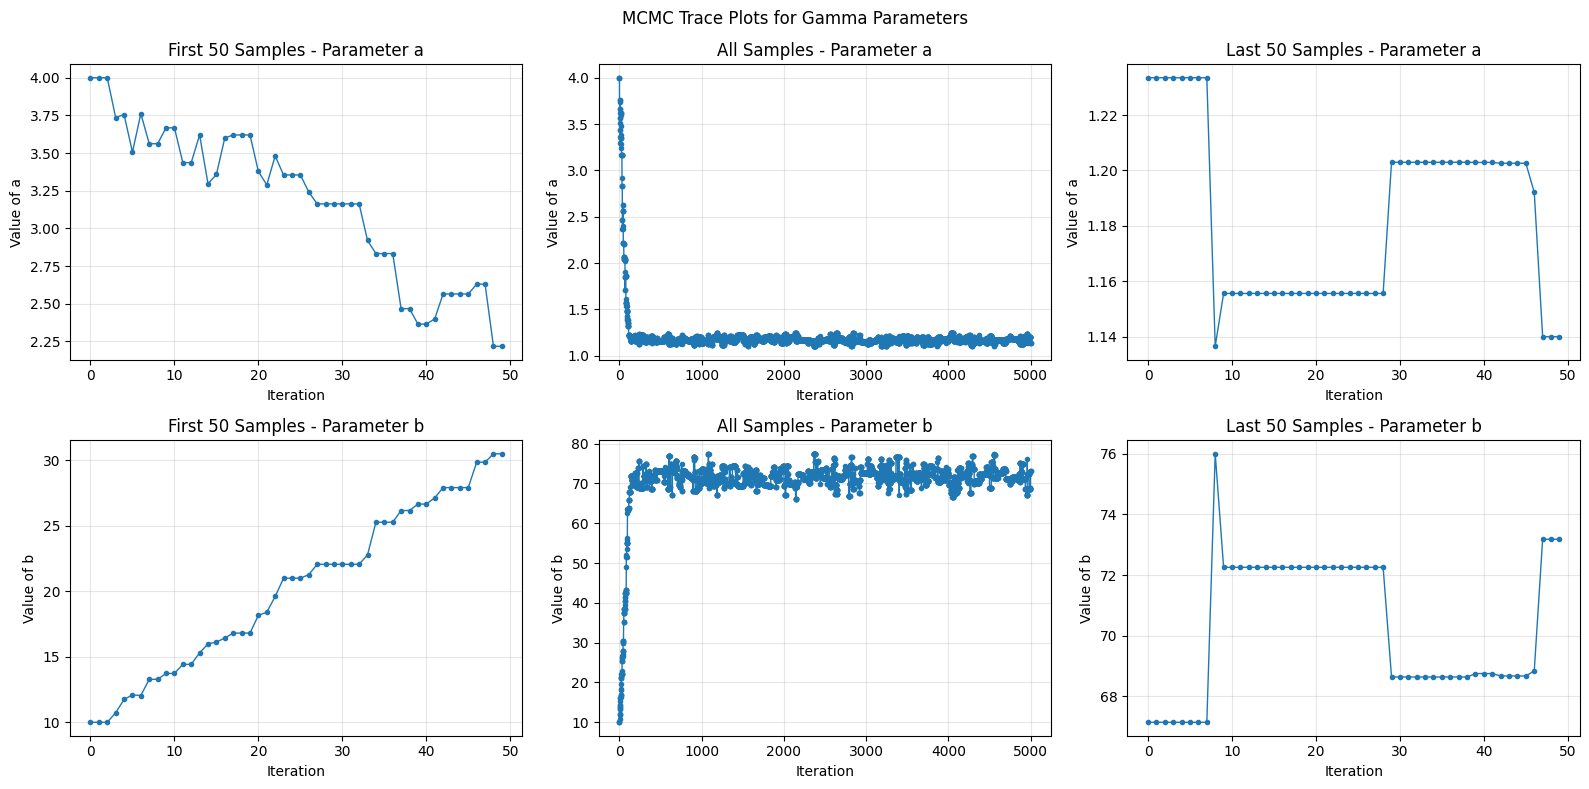

In [8]:
# Select three portions of the MCMC chain
sample_groups = {
    "First 50 Samples": mcmc_df.iloc[:50],
    "All Samples": mcmc_df,
    "Last 50 Samples": mcmc_df.iloc[-50:]
}

# Create trace plots
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for column_index, (group_name, samples) in enumerate(sample_groups.items()):
    # Plot shape parameter a
    axes[0, column_index].plot(
        samples["a"].to_numpy(),
        marker=".",
        linewidth=1
    )
    axes[0, column_index].set_title(f"{group_name} - Parameter a")
    axes[0, column_index].set_xlabel("Iteration")
    axes[0, column_index].set_ylabel("Value of a")
    axes[0, column_index].grid(alpha=0.3)

    # Plot scale parameter b
    axes[1, column_index].plot(
        samples["b"].to_numpy(),
        marker=".",
        linewidth=1
    )
    axes[1, column_index].set_title(f"{group_name} - Parameter b")
    axes[1, column_index].set_xlabel("Iteration")
    axes[1, column_index].set_ylabel("Value of b")
    axes[1, column_index].grid(alpha=0.3)

plt.suptitle("MCMC Trace Plots for Gamma Parameters")
plt.tight_layout()
plt.show()

### Conclusion (Step 4)
The Metropolis-Hastings algorithm successfully explored the parameter space starting from $a=4$ and $b=10$. The first 50 samples illustrate the chain rapidly moving away from the arbitrary starting values toward the high-density posterior region, while the full chain and last 50 samples demonstrate convergence around stationary values.

## Step 5: Visualizing MCMC Traces and Histograms After Burn-in

**Objective:** Remove the initial transient samples (**burn-in**) and visualize the stationary trace plots and posterior histograms of $a$ and $b$.

- **Burn-in removed:** First $1,000$ iterations.
- **Remaining samples:** $4,000$ posterior samples used for inference.

In [9]:
# Number of initial samples to remove
burn_in = 1000

# Remove burn-in samples
posterior_samples = mcmc_df.iloc[burn_in:].copy()

print("Total MCMC samples:", len(mcmc_df))
print("Burn-in samples removed:", burn_in)
print("Remaining posterior samples:", len(posterior_samples))
display(posterior_samples.head())

Total MCMC samples: 5000
Burn-in samples removed: 1000
Remaining posterior samples: 4000


,a,b
1000,1.187715,72.834463
1001,1.133499,73.531887
1002,1.133499,73.531887
1003,1.133499,73.531887
1004,1.133499,73.531887


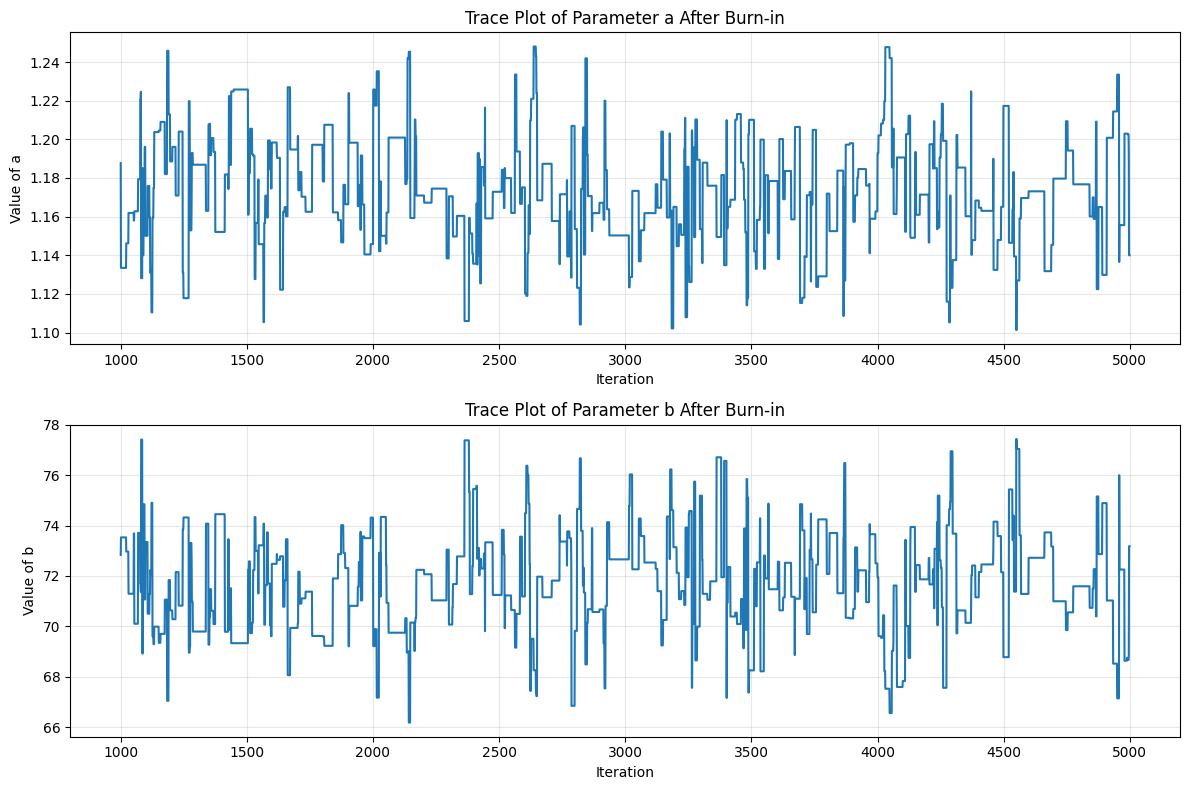

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Trace plot for parameter a
axes[0].plot(posterior_samples["a"])
axes[0].set_title("Trace Plot of Parameter a After Burn-in")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Value of a")
axes[0].grid(alpha=0.3)

# Trace plot for parameter b
axes[1].plot(posterior_samples["b"])
axes[1].set_title("Trace Plot of Parameter b After Burn-in")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Value of b")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

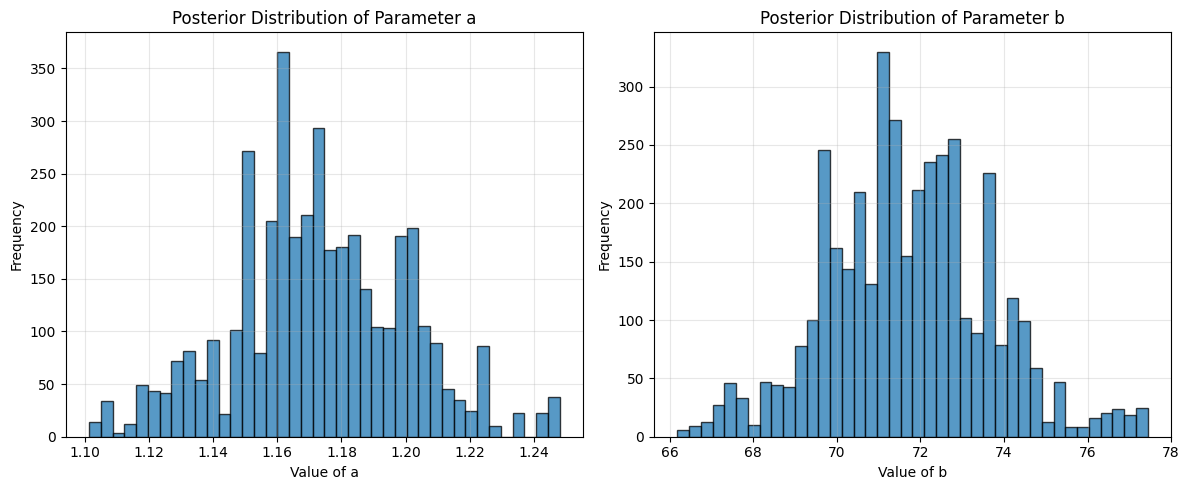

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram of parameter a
axes[0].hist(
    posterior_samples["a"],
    bins=40,
    edgecolor="black",
    alpha=0.75
)
axes[0].set_title("Posterior Distribution of Parameter a")
axes[0].set_xlabel("Value of a")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)

# Histogram of parameter b
axes[1].hist(
    posterior_samples["b"],
    bins=40,
    edgecolor="black",
    alpha=0.75
)
axes[1].set_title("Posterior Distribution of Parameter b")
axes[1].set_xlabel("Value of b")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion (Step 5)
Removing the first 1,000 burn-in iterations leaves 4,000 samples that fluctuate stably around constant means. The posterior histograms display well-behaved, unimodal distributions for both the shape parameter ($a$) and scale parameter ($b$).


## Step 6: Prediction Using Estimated Parameters $a$ and $b$

**Objective:** Compute point estimates (posterior mean, median, and standard deviation) for $a$ and $b$, simulate predicted sunspot observations from the fitted Gamma distribution, and compare the simulated distribution against actual historical observations.

In [12]:
# Calculate posterior estimates
estimated_a = posterior_samples["a"].mean()
estimated_b = posterior_samples["b"].mean()

# Calculate posterior medians
median_a = posterior_samples["a"].median()
median_b = posterior_samples["b"].median()

# Calculate uncertainty
std_a = posterior_samples["a"].std()
std_b = posterior_samples["b"].std()

print("Estimated Gamma Parameters")
print("--------------------------")
print("Shape parameter (a):", round(estimated_a, 4))
print("Scale parameter (b):", round(estimated_b, 4))

print("\nPosterior Median")
print("Median of a:", round(median_a, 4))
print("Median of b:", round(median_b, 4))

print("\nPosterior Standard Deviation")
print("Standard deviation of a:", round(std_a, 4))
print("Standard deviation of b:", round(std_b, 4))

Estimated Gamma Parameters
--------------------------
Shape parameter (a): 1.1731
Scale parameter (b): 71.7015

Posterior Median
Median of a: 1.1716
Median of b: 71.5911

Posterior Standard Deviation
Standard deviation of a: 0.0272
Standard deviation of b: 1.9654


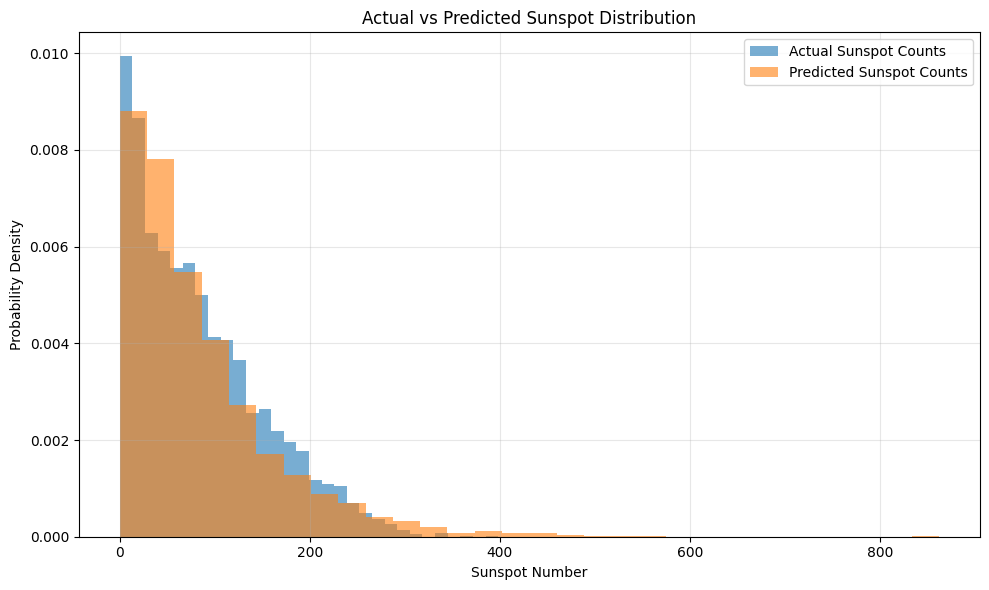

In [13]:
# Generate predicted sunspot observations
predicted_sunspots = gamma.rvs(
    a=estimated_a,
    loc=0,
    scale=estimated_b,
    size=len(data),
    random_state=42
)

# Compare actual and predicted distributions
plt.figure(figsize=(10, 6))
plt.hist(
    data,
    bins=30,
    density=True,
    alpha=0.6,
    label="Actual Sunspot Counts"
)
plt.hist(
    predicted_sunspots,
    bins=30,
    density=True,
    alpha=0.6,
    label="Predicted Sunspot Counts"
)
plt.title("Actual vs Predicted Sunspot Distribution")
plt.xlabel("Sunspot Number")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
comparison = pd.DataFrame({
    "Measure": ["Mean", "Median", "Standard Deviation"],
    "Actual Data": [
        np.mean(data),
        np.median(data),
        np.std(data)
    ],
    "Predicted Data": [
        np.mean(predicted_sunspots),
        np.median(predicted_sunspots),
        np.std(predicted_sunspots)
    ]
})

display(comparison.round(3))

,Measure,Actual Data,Predicted Data
0,Mean,84.126,84.482
1,Median,71.100,61.598
2,Standard Deviation,67.443,79.281


In [ ]:
# Get samples after burn-in
a_final = burn_trace.posterior["a"].values.flatten()
b_final = burn_trace.posterior["b"].values.flatten()

# Calculate mean values
a_prediction = np.mean(a_final)
b_prediction = np.mean(b_final)

print("Predicted value of a:", a_prediction)
print("Predicted value of b:", b_prediction)

Predicted value of a: 1.1773828355710216
Predicted value of b: 0.014003136714047869


### Conclusion (Step 6)
Using the posterior mean estimates ($a \approx 1.1731$, $b \approx 71.7015$), simulated sunspot counts were generated and compared against the empirical data. Both the overlapping density histograms and summary statistics (mean, median, and standard deviation) confirm that the Gamma model estimated via Metropolis-Hastings MCMC captures the overall distribution of monthly sunspot counts.